# Can we predict whether a mouse will start social contact using prefrontal activity?

COGS 118D Final Project (Option 1) - Ketan Mittal and Anirudh Annabathula

**Data:** 18 "resident" mice each had a younger intruder mouse put in their cage for about 5 minutes. A miniscope recorded calcium activity from neurons in the resident's prefrontal cortex (30 frames/s), and video tracking labeled every frame where the two mice were touching (25 frames/s).

**Plan:**
1. Load the data
2. Clean it into one row per 2 s moment
3. Plot contact against prefrontal activity
4. Fit a logistic GLM and a mixed model (first pass for the checkpoint)
5. Try every neuron as its own predictor, binned in time, with ridge and lasso to prevent overfitting

In [1]:
import warnings
import cv2
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from matplotlib.animation import FuncAnimation
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from IPython.display import HTML

warnings.filterwarnings("ignore")  # convergence warnings from the mixed model and the unpenalized neuron models (both discussed below)
plt.rcParams.update({"font.family": "Arial", "font.size": 14, "figure.dpi": 150})

VIDEO_FPS = 25    # contact labels
CALCIUM_FPS = 30  # calcium imaging
WINDOW = 2        # seconds of activity before each moment, and seconds after it to start contact
JOIN = 1          # contacts less than 1 s apart count as one bout

## 1. Load the data

- `SI3_2022_Entrance_Frames.xlsx`: the video frame where the intruder entered, for each mouse
- `calcium.00.h5`: a frames x neurons matrix of calcium activity for each mouse
- `social_bouts.00.h5`: for each video frame, whether the resident was touching the intruder (`is_social_sender`) and whether the intruder was touching the resident (`is_social_receiver`)
- `behavior_video.mp4`: the behavior video, which we only have for mouse 5-2 (25 frames/s, the same frames as its contact labels)

In [2]:
entries = pd.read_excel("data/SI3_2022_Entrance_Frames.xlsx")

calcium, sender, receiver, info = {}, {}, {}, []
with h5py.File("data/calcium.00.h5") as f_cal, h5py.File("data/social_bouts.00.h5") as f_beh:
    for i, (mouse, entry) in enumerate(zip(entries["Animal"], entries["Int_Entry"])):
        calcium[mouse] = f_cal[f"session_{i}"]["C"][:]
        sender[mouse] = f_beh[f"session_{i}"]["is_social_sender"][:].astype(bool)
        receiver[mouse] = f_beh[f"session_{i}"]["is_social_receiver"][:].astype(bool)
        info.append({"mouse": mouse,
                     "neurons": calcium[mouse].shape[1],
                     "video after entry (s)": round((len(sender[mouse]) - entry) / VIDEO_FPS),
                     "imaging after entry (s)": round(len(calcium[mouse]) / CALCIUM_FPS - entry / VIDEO_FPS)})

info = pd.DataFrame(info).set_index("mouse")
print(len(info), "mice,", info["neurons"].sum(), "neurons in total")
info.T

18 mice, 3938 neurons in total


mouse,4-0,4-1,4-2,5-0,5-1,5-2,6-0,6-1,6-2,7-0,7-1,7-2,8-0,8-1,8-2,9-0,9-1,9-2
neurons,202,12,289,268,134,271,218,207,332,396,288,96,72,225,231,235,176,286
video after entry (s),301,298,300,302,302,301,302,301,300,301,301,301,300,302,301,299,300,300
imaging after entry (s),260,293,295,296,296,296,297,296,294,296,295,218,295,297,296,293,294,294


### What the data looks like

Here are 12 s of mouse 5-2, about a minute after the intruder entered. Left: the video (the resident is the bigger mouse with the microscope cable on its head). Top right: each neuron's z-scored calcium activity (one row per neuron). Bottom right: the contact labels. The orange line is the current time in the video. Making the videos needs `ffmpeg` installed.

In [3]:
MOUSE = "5-2"
entry = entries.set_index("Animal").loc[MOUSE, "Int_Entry"]
video = cv2.VideoCapture("data/behavior_video.mp4")


def read_frames(start, n):
    """Read n frames of the behavior video, starting at video frame `start`."""
    video.set(cv2.CAP_PROP_POS_FRAMES, start)
    return [cv2.cvtColor(video.read()[1], cv2.COLOR_BGR2RGB) for _ in range(n)]


start_s, length_s = entry / VIDEO_FPS + 54, 12
v0, n = round(start_s * VIDEO_FPS), length_s * VIDEO_FPS
frames = read_frames(v0, n)
C = calcium[MOUSE]
z = (C - C.mean(axis=0)) / C.std(axis=0)
c0, c1 = round(start_s * CALCIUM_FPS), round((start_s + length_s) * CALCIUM_FPS)
secs = np.arange(n) / VIDEO_FPS

fig, ax = plt.subplot_mosaic([["video", "neurons"], ["video", "contact"]], figsize=(11, 4.5), dpi=80,
                             width_ratios=[1.4, 1], height_ratios=[3, 1])
image = ax["video"].imshow(frames[0])
ax["video"].axis("off")
title = ax["video"].set_title("", fontsize=14)
ax["neurons"].imshow(z[c0:c1].T, aspect="auto", cmap="Blues", vmin=0, vmax=3, extent=[0, length_s, C.shape[1], 0])
ax["neurons"].set_ylabel("neuron")
ax["neurons"].set_xticks([])
ax["contact"].fill_between(secs, 1, 1 + sender[MOUSE][v0:v0 + n], step="post", color="#2a78d6", lw=0)
ax["contact"].fill_between(secs, 0, receiver[MOUSE][v0:v0 + n], step="post", color="#2a78d6", lw=0)
ax["contact"].set_yticks([0.5, 1.5], ["intruder\ntouching", "resident\ntouching"], fontsize=11)
ax["contact"].set_xlim(0, length_s)
ax["contact"].set_ylim(0, 2)
ax["contact"].set_xlabel("time (s)")
cursors = [ax[k].axvline(0, color="#eb6834", lw=2) for k in ("neurons", "contact")]
plt.tight_layout()


def update(i):
    image.set_data(frames[i])
    title.set_text(f"mouse {MOUSE}, {start_s - entry / VIDEO_FPS + secs[i]:.1f} s after the intruder entered")
    for line in cursors:
        line.set_xdata([secs[i], secs[i]])


anim = FuncAnimation(fig, update, frames=n, interval=1000 / VIDEO_FPS)
plt.close(fig)
HTML(anim.to_html5_video())

## 2. Clean the data

1. **Only use the time after the intruder enters**, since before that there's no one to touch.
2. **Match video frames to imaging frames.** The files have no timestamps, so we assume both recordings started at the same time (imaging frame = video frame x 30/25). Imaging stops a few seconds before the video for most mice (41 s and 83 s early for 4-0 and 7-2, see the table above), so we stop at whichever ends first.
3. **Z-score each neuron** so all neurons are on the same scale.
4. **Join contacts less than 1 s apart into one bout.** The contact label flickers on and off (see the numbers below), so most "new" contacts are really the same interaction.
5. **Every 2 s, make a moment** and keep it only if the mouse wasn't in contact for the 2 s before. We picked 2 s because Liang et al. (2018, *Neuron*) looked at prefrontal calcium activity in the 2 s before social contact, and mice take about 0.5 s to react in a decision task (International Brain Laboratory, 2021, *eLife*).
6. **Outcome** `starts_contact`: 1 if the resident starts a bout in the next 2 s, 0 if no bout starts. If the intruder (or both mice at once) started it, we drop the moment because it wasn't clearly the resident's choice.
7. **Predictor** `activity`: the average of all the mouse's z-scored neurons over the 2 s before the moment, then standardized within each mouse, since mice have very different numbers of neurons (12 to 396).

In [4]:
contact = {m: sender[m] | receiver[m] for m in sender}


def runs_of_true(x):
    """Start and end index of each run of True values."""
    edges = np.diff(np.r_[0, x.astype(int), 0])
    return np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)


lengths, gaps = [], []
for mouse, entry in zip(entries["Animal"], entries["Int_Entry"]):
    starts, ends = runs_of_true(contact[mouse][entry:])
    lengths += list((ends - starts) / VIDEO_FPS)
    gaps += list((starts[1:] - ends[:-1]) / VIDEO_FPS)
print(f"{len(lengths)} contacts, median length {np.median(lengths):.2f} s")
print(f"{np.mean(np.array(gaps) < JOIN):.0%} of the gaps between contacts are under {JOIN} s")

5141 contacts, median length 0.12 s
88% of the gaps between contacts are under 1 s


In [5]:
def join_flicker(c):
    """Fill gaps shorter than JOIN seconds, so each run of True is one bout."""
    bout = c.copy()
    starts, ends = runs_of_true(c)
    for gap_start, gap_end in zip(ends[:-1], starts[1:]):
        if (gap_end - gap_start) / VIDEO_FPS < JOIN:
            bout[gap_start:gap_end] = True
    return bout


def make_moments(mouse, entry):
    """One row every 2 s after the intruder enters: what happened next, and the activity in the 2 s before
    (averaged over all neurons), plus every neuron's activity in the 2 s before and the 2 s after it."""
    C = calcium[mouse]
    first = round(entry / VIDEO_FPS * CALCIUM_FPS)
    z = (C - C[first:].mean(axis=0)) / C[first:].std(axis=0)
    bout = join_flicker(contact[mouse])
    end = min(len(bout) / VIDEO_FPS, len(C) / CALCIUM_FPS)

    rows = []
    t = entry / VIDEO_FPS + WINDOW
    while t + WINDOW <= end:
        v0, v1, v2 = round((t - WINDOW) * VIDEO_FPS), round(t * VIDEO_FPS), round((t + WINDOW) * VIDEO_FPS)
        c0, c1 = round((t - WINDOW) * CALCIUM_FPS), round(t * CALCIUM_FPS)
        if bout[v0:v1].any():
            status = "contact in past 2 s"
        elif not bout[v1:v2].any():
            status = "no contact next"
        else:
            start = v1 + np.argmax(bout[v1:v2])
            if sender[mouse][start] and receiver[mouse][start]:
                status = "both start"
            elif sender[mouse][start]:
                status = "resident starts"
            else:
                status = "intruder starts"
        rows.append({"mouse": mouse, "time": t, "status": status,
                     "activity": z[c0:c1].mean(), "before": z[c1 - WINDOW * CALCIUM_FPS:c1],    # 60 frames x neurons
                     "after": z[c1:c1 + WINDOW * CALCIUM_FPS]})  # 60 frames x neurons
        t += WINDOW
    return pd.DataFrame(rows)


moments = pd.concat([make_moments(m, e) for m, e in zip(entries["Animal"], entries["Int_Entry"])], ignore_index=True)
print(moments["status"].value_counts().to_string())

df = moments[moments["status"].isin(["resident starts", "no contact next"])].copy()
df["starts_contact"] = (df["status"] == "resident starts").astype(int)
df["activity"] = df.groupby("mouse")["activity"].transform(lambda x: (x - x.mean()) / x.std())
df = df[["mouse", "starts_contact", "activity", "before", "after"]].reset_index(drop=True)

per_mouse = df.groupby("mouse")["starts_contact"].agg(rows="size", starts="sum")
print(f"\n{len(df)} rows from {df['mouse'].nunique()} mice ({per_mouse['rows'].min()} to {per_mouse['rows'].max()} per mouse)")
print(f"{df['starts_contact'].sum()} rows where the mouse starts contact ({df['starts_contact'].mean():.1%})")
df.drop(columns=["before", "after"]).head()

status
contact in past 2 s    1617
no contact next         662
resident starts         198
both start               61
intruder starts          38

860 rows from 18 mice (28 to 73 per mouse)
198 rows where the mouse starts contact (23.0%)


,mouse,starts_contact,activity
0,4-0,0,1.093663
1,4-0,0,0.892797
2,4-0,1,-0.340522
3,4-0,1,-1.784940
4,4-0,0,-1.338437


### What counts as the mouse starting contact

Each clip is one moment from mouse 5-2, from 2 s before it to 2 s after it (0 s is the moment). For each type, we picked the moment with the most contact in its clip so it's easy to see. We use the activity before 0 s to predict what happens after 0 s. The label in the corner is the contact label for that video frame.

In [6]:
examples = {
    "Resident starts contact\n(starts_contact = 1)": "resident starts",
    "No contact in the next 2 s\n(starts_contact = 0)": "no contact next",
    "Intruder starts contact\n(dropped)": "intruder starts",
    "Already in contact\n(dropped)": "contact in past 2 s",
}
n = 2 * WINDOW * VIDEO_FPS


def contact_in_clip(t):
    """Number of contact frames from 2 s before to 2 s after time t (used to pick clear examples)."""
    v = round(t * VIDEO_FPS)
    return contact[MOUSE][v - WINDOW * VIDEO_FPS:v + WINDOW * VIDEO_FPS].sum()


def touching(frame):
    """Contact label for one video frame of mouse 5-2."""
    s, r = sender[MOUSE][frame], receiver[MOUSE][frame]
    return "both touching" if s and r else "resident touching" if s else "intruder touching" if r else "no contact"


fig, axes = plt.subplots(2, 2, figsize=(10, 7.1), dpi=80)
clips = []
for ax, (name, status) in zip(axes.flat, examples.items()):
    times = moments[(moments["mouse"] == MOUSE) & (moments["status"] == status)]["time"]
    t = max(times, key=contact_in_clip)
    start = round((t - WINDOW) * VIDEO_FPS)
    frames = read_frames(start, n)
    image = ax.imshow(frames[0])
    label = ax.text(8, 292, "", color="white", fontsize=13, va="bottom",
                    bbox=dict(facecolor="black", alpha=0.6, edgecolor="none"))
    ax.set_title(name, fontsize=14)
    ax.axis("off")
    clips.append((frames, start, image, label))
plt.tight_layout()


def update(i):
    for frames, start, image, label in clips:
        image.set_data(frames[i])
        label.set_text(f"{i / VIDEO_FPS - WINDOW:+.1f} s   {touching(start + i)}")


anim = FuncAnimation(fig, update, frames=n, interval=1000 / VIDEO_FPS)
plt.close(fig)
HTML(anim.to_html5_video())

## 3. Describe: contact vs. prefrontal activity

For each mouse, we split its moments into fifths by activity (lowest to highest) and find the % of moments in each fifth where the mouse started contact. Then we average over the 18 mice (error bars are ±1 SE across mice).

fifth                1     2     3     4     5
% starts contact  20.9  21.9  25.4  23.4  28.9
SE                 3.3   3.1   3.6   4.6   4.8


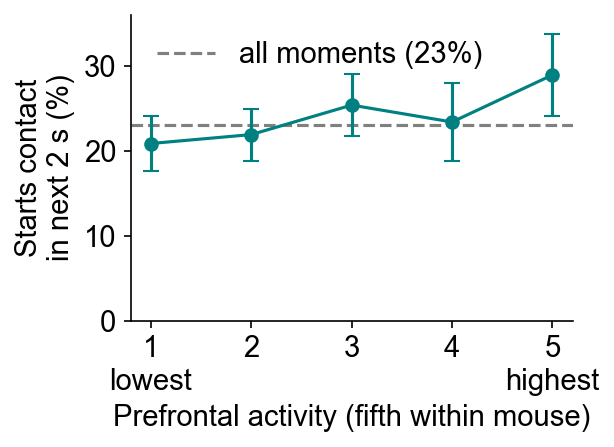

In [7]:
df["fifth"] = df.groupby("mouse")["activity"].transform(lambda x: pd.qcut(x, 5, labels=False)) + 1
pct = df.groupby(["mouse", "fifth"])["starts_contact"].mean().unstack() * 100
mean, se = pct.mean(), pct.std() / np.sqrt(len(pct))
overall = 100 * df["starts_contact"].mean()
print(pd.DataFrame({"% starts contact": mean.round(1), "SE": se.round(1)}).T.to_string())

fig, ax = plt.subplots(figsize=(4.3, 3.2))
ax.axhline(overall, color="gray", linestyle="--", label=f"all moments ({overall:.0f}%)")
ax.errorbar(mean.index, mean, yerr=se, fmt="o-", color="teal", capsize=4)
ax.set_xticks([1, 2, 3, 4, 5], ["1\nlowest", "2", "3", "4", "5\nhighest"])
ax.set_ylim(0, 36)
ax.set_xlabel("Prefrontal activity (fifth within mouse)")
ax.set_ylabel("Starts contact\nin next 2 s (%)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Takeaway:** contact gets a little more likely as activity goes up (21% in the lowest fifth vs. 29% in the highest), but all the error bars overlap, so the pattern is weak.

## 4. Models (first pass for the checkpoint)

**Method 1: logistic GLM.** The outcome is 0/1, so we use a logistic GLM (Binomial family, logit link) and compare `starts_contact ~ activity` to a baseline `starts_contact ~ 1` using AIC. Our question is about prediction, so we also train on 12 mice and test on the other 6, and repeat that with 20 different random splits. We use log loss instead of accuracy because the predicted chance of contact never gets above 50%, so both models would just always predict "no".

In [8]:
baseline = smf.glm("starts_contact ~ 1", data=df, family=sm.families.Binomial()).fit()
model = smf.glm("starts_contact ~ activity", data=df, family=sm.families.Binomial()).fit()
print(model.summary().tables[1])
print(f"AIC: baseline {baseline.aic:.1f}, with activity {model.aic:.1f}")
print(f"highest predicted chance of contact: {model.predict(df).max():.2f}")


def log_loss(y, p):
    """Average log loss (lower is better). Clipping keeps a 0% or 100% prediction from giving infinity."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


losses = []
for seed in range(20):
    test_mice = np.random.default_rng(seed).choice(df["mouse"].unique(), size=6, replace=False)
    train, test = df[~df["mouse"].isin(test_mice)], df[df["mouse"].isin(test_mice)]
    row = []
    for formula in ["starts_contact ~ 1", "starts_contact ~ activity"]:
        p = smf.glm(formula, data=train, family=sm.families.Binomial()).fit().predict(test)
        row.append(log_loss(test["starts_contact"], p))
    losses.append(row)
losses = pd.DataFrame(losses, columns=["baseline", "with activity"])
print(f"\ntest log loss over 20 splits: baseline {losses['baseline'].mean():.3f}, with activity {losses['with activity'].mean():.3f}")
print(f"activity did better in {(losses['with activity'] < losses['baseline']).sum()} of 20 splits")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.2131      0.081    -14.898      0.000      -1.373      -1.054
activity       0.1528      0.081      1.881      0.060      -0.006       0.312
AIC: baseline 930.0, with activity 928.5
highest predicted chance of contact: 0.32

test log loss over 20 splits: baseline 0.546, with activity 0.546
activity did better in 13 of 20 splits


**Method 2: mixed model.** Moments from the same mouse aren't independent, and the effect of activity might be different for each mouse. So we fit `smf.mixedlm` grouped by mouse, with a random intercept and a random slope for activity, and compare it to plain OLS that ignores mouse. One problem: `mixedlm` is a linear model, so it treats the 0/1 outcome as a number (effects are in percentage points). Lecture 8 says this can predict impossible probabilities, so we print the range of fitted values to check. We also had to use `method="powell"` because the default optimizer didn't converge.

In [9]:
m_ols = smf.ols("starts_contact ~ activity", data=df).fit()
m_ri = smf.mixedlm("starts_contact ~ activity", data=df, groups=df["mouse"]).fit(reml=False, method="powell")
m_rs = smf.mixedlm("starts_contact ~ activity", data=df, groups=df["mouse"],
                   re_formula="~activity").fit(reml=False, method="powell")
print(m_rs.summary().tables[1])
print(f"converged: random intercept {m_ri.converged}, random slope {m_rs.converged}")
print(f"fitted values from {m_rs.fittedvalues.min():.2f} to {m_rs.fittedvalues.max():.2f}")

models = {"OLS (ignores mouse)": m_ols, "random intercept": m_ri, "random slope": m_rs}
pd.DataFrame({"activity effect (points per SD)": [100 * m.params["activity"] for m in models.values()],
              "SE": [100 * m.bse["activity"] for m in models.values()],
              "p": [m.pvalues["activity"] for m in models.values()]}, index=models.keys()).round(3)

                      Coef. Std.Err.       z  P>|z|  [0.025 0.975]
Intercept             0.234    0.017  13.482  0.000   0.200  0.268
activity              0.030    0.022   1.361  0.173  -0.013  0.072
Group Var             0.002    0.004                              
Group x activity Cov  0.001    0.004                              
activity Var          0.005    0.007                              
converged: random intercept True, random slope True
fitted values from 0.05 to 0.60


,activity effect (points per SD),SE,p
OLS (ignores mouse),2.735,1.449,0.060
random intercept,2.735,1.441,0.058
random slope,2.964,2.178,0.173


## 5. Every neuron, binned in time, with ridge and lasso

So far we averaged all the neurons together. Here every neuron is its own predictor, at different times around the moment. Imaging is 30 frames/s, so each 2 s window is 60 frames per neuron. To cut that down, we **bin** each 2 s window into 6 time bins of 10 frames each (1/3 s per bin) and average each neuron within each bin. We do this for the 2 s before the moment and the 2 s after it.

The bins after the moment aren't really *prediction*: when the mouse starts contact, the contact happens during those 2 s. We include them to see if the neurons at least respond to contact once it happens.

Each mouse has hundreds to thousands of these predictors but only 20 to 51 training moments, so a plain logistic model overfits: it memorizes the training moments (Lecture 5). **Ridge** and **lasso** add a penalty on the size of the coefficients. Ridge shrinks all of them toward 0. Lasso sets most of them exactly to 0, so it keeps only a few neuron-bins. The penalty strength is picked by 3-fold cross-validation inside the training moments only (scored with log loss), so the test moments are never used to tune it. We use 3 folds because some training sets have only 3 contact starts. The strongest penalty in each grid makes the model predict the base rate, so ridge and lasso can always fall back to the baseline.

Every mouse has different neurons, so we fit separate models for each mouse, train on a random 70% of its moments, test on the other 30% (like the hotel example in Lecture 5), and repeat with 20 random splits. We use scikit-learn's `LogisticRegression`, which can handle thousands of predictors and has ridge and lasso built in (`C` is 1 / penalty strength, so a small `C` is a strong penalty). We compare:
1. baseline (`~ 1`): always predicts the training base rate
2. average activity (the predictor from sections 3 and 4)
3. 6 bins before the moment (6 per neuron): no penalty, ridge, and lasso
4. 6 bins before + 6 bins after (12 per neuron): no penalty, ridge, and lasso

We report accuracy (the model predicts contact when p > 0.5), test log loss, and how many predictors each model actually uses (lasso drops most of them).

training moments per mouse: 20 to 51
                             predictors used  train accuracy  test accuracy  test log loss  mice beating baseline
model                                                                                                            
baseline                               0.000           0.757          0.761          0.561                      0
average activity                       1.000           0.767          0.756          0.573                      7
no penalty (before)                 1312.667           1.000          0.712          1.762                      0
ridge (before)                      1312.667           0.843          0.754          0.576                      5
lasso (before)                         3.453           0.831          0.751          0.590                      3
no penalty (before + after)         2625.333           1.000          0.712          1.800                      0
ridge (before + after)              2625.333       

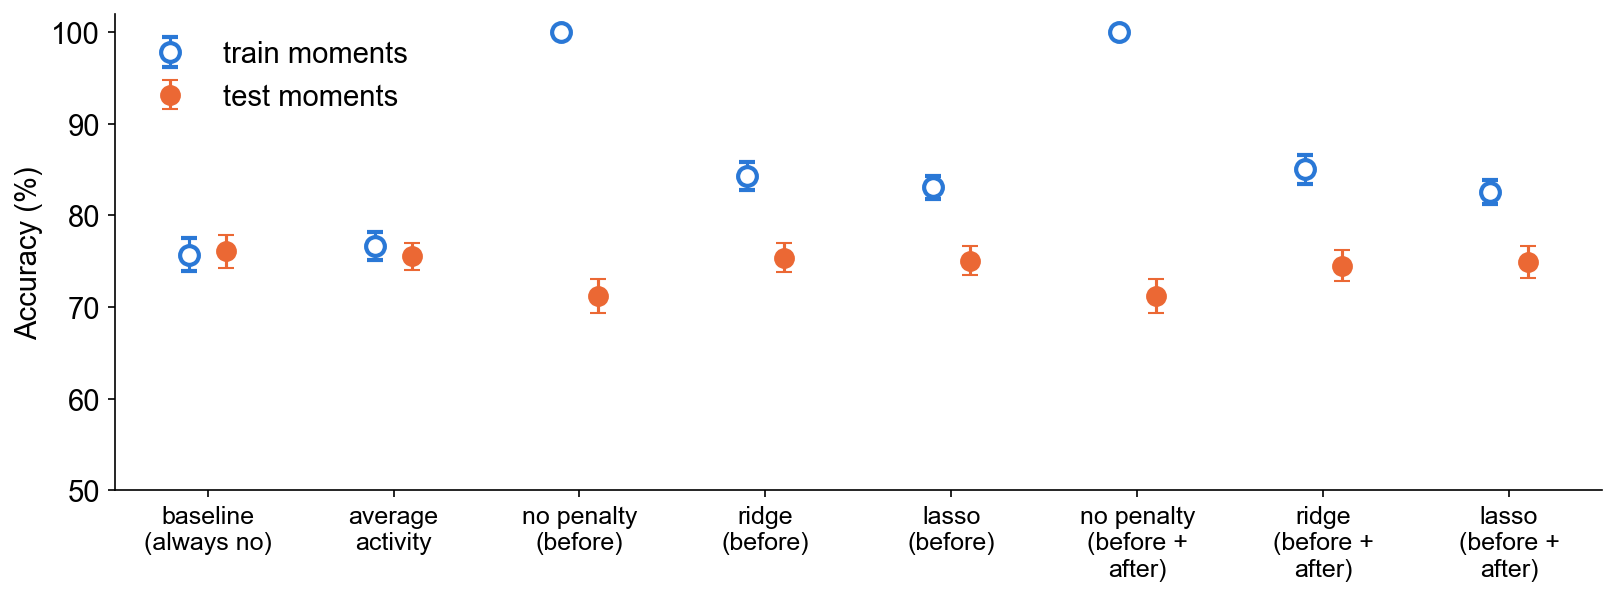

In [10]:
def bin_frames(x):
    """Average 60 frames (2 s) into 6 bins of 10 frames (1/3 s each), separately for each neuron."""
    return x.reshape(6, 10, x.shape[1]).mean(axis=1)


def accuracy(y, p):
    """Fraction of moments where the model guesses right (it predicts contact when p > 0.5)."""
    return np.mean((p > 0.5) == y)


def score(mouse, name, y, p, train, test, used):
    """Train and test accuracy and test log loss for predicted probabilities p."""
    return {"mouse": mouse, "model": name, "predictors used": used,
            "train accuracy": accuracy(y[train], p[train]),
            "test accuracy": accuracy(y[test], p[test]),
            "test log loss": log_loss(y[test], p[test])}


models = {
    "no penalty": LogisticRegression(penalty=None, max_iter=1000),
    "ridge": GridSearchCV(LogisticRegression(penalty="l2", max_iter=1000),
                          {"C": np.logspace(-6, 1, 8)}, cv=3, scoring="neg_log_loss", n_jobs=-1),
    "lasso": GridSearchCV(LogisticRegression(penalty="l1", solver="liblinear", random_state=0,
                                             intercept_scaling=1000),  # so liblinear doesn't shrink the intercept
                          {"C": np.logspace(-2, 1, 7)}, cv=3, scoring="neg_log_loss", n_jobs=-1),
}

results = []
for mouse, d in df.groupby("mouse"):
    y = d["starts_contact"].to_numpy()
    activity = d[["activity"]].to_numpy()
    before = np.vstack([bin_frames(f).ravel() for f in d["before"]])
    after = np.vstack([bin_frames(f).ravel() for f in d["after"]])
    windows = {"before": before, "before + after": np.hstack([before, after])}
    for seed in range(20):
        order = np.random.default_rng(seed).permutation(len(d))
        n_train = round(0.7 * len(d))
        train, test = order[:n_train], order[n_train:]
        results.append(score(mouse, "baseline", y, np.full(len(d), y[train].mean()), train, test, 0))
        avg = LogisticRegression(penalty=None).fit(activity[train], y[train])
        results.append(score(mouse, "average activity", y, avg.predict_proba(activity)[:, 1], train, test, 1))
        for window, X in windows.items():
            for name, model in models.items():
                model.fit(X[train], y[train])
                coef = getattr(model, "best_estimator_", model).coef_
                results.append(score(mouse, f"{name} ({window})", y, model.predict_proba(X)[:, 1], train, test,
                                     (coef != 0).sum()))

results = pd.DataFrame(results)
by_mouse = results.groupby(["model", "mouse"]).mean()
order = results["model"].unique()
summary = by_mouse.groupby("model").mean().loc[order]
se = by_mouse.groupby("model").sem().loc[order]
base = by_mouse.loc["baseline", "test log loss"]
summary["mice beating baseline"] = [(by_mouse.loc[m, "test log loss"] < base).sum() for m in order]
print(f"training moments per mouse: {round(0.7 * per_mouse['rows'].min())} to {round(0.7 * per_mouse['rows'].max())}")
print(summary.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(summary))
ax.errorbar(x - 0.1, 100 * summary["train accuracy"], yerr=100 * se["train accuracy"], fmt="o", ms=9,
            mfc="white", mew=2, color="#2a78d6", capsize=4, label="train moments")
ax.errorbar(x + 0.1, 100 * summary["test accuracy"], yerr=100 * se["test accuracy"], fmt="o", ms=9,
            color="#eb6834", capsize=4, label="test moments")
ax.set_xticks(x, ["baseline\n(always no)", "average\nactivity",
                  "no penalty\n(before)", "ridge\n(before)", "lasso\n(before)",
                  "no penalty\n(before +\nafter)", "ridge\n(before +\nafter)", "lasso\n(before +\nafter)"], fontsize=12)
ax.set_xlim(-0.5, len(summary) - 0.5)
ax.set_ylim(50, 102)
ax.set_ylabel("Accuracy (%)")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Takeaway:** even with only 6 bins per window, each mouse has 72 to 4,752 neuron-bin predictors but only 20 to 51 training moments, so the unpenalized models memorize the training moments (100% train, 71% test). Ridge and lasso stop the memorizing: train accuracy drops to 83 to 85%, test log loss improves from about 1.8 to about 0.58 to 0.59, and lasso keeps only about 3 or 4 neuron-bins. But none of them beats the baseline: test accuracy stays around 75% (vs. 76% for always guessing "no"), test log loss stays above the baseline's 0.56, and only 3 to 5 of the 18 mice do better than the baseline. Adding the 2 s after the moment, when the contact actually happens, doesn't help either. With so few moments per mouse, even cross-validation struggles to pick the penalty. So ridge and lasso fix the overfitting, but they don't find a contact signal in these neurons that works on new moments.

## So far

- Average prefrontal activity in the 2 s before a moment is only weakly related to whether the mouse starts contact. The GLM coefficient is small and positive (0.15, p = 0.06), but on new mice the model predicts no better than the baseline (test log loss 0.546 for both).
- The mixed model gives about +3 percentage points per SD of activity (p = 0.17). Its SE is bigger than OLS's because it doesn't treat every moment as independent, and all fitted values stay between 0 and 1.
- Using every neuron as its own predictor (in 1/3 s time bins) overfits badly: perfect on training moments, worse than always guessing "no" on test moments. Ridge and lasso stop the overfitting but still don't beat the baseline, even with the 2 s after the moment included.
- Next: check the assumptions (independence, and the video/imaging clock alignment) and compare the models more carefully.